# 02 — Phân tích lỗi (nhánh 13)

Đọc báo cáo **từng mẫu** do nhánh 10 ghi (`reports/<model>_<domain>.csv`) rồi:
- độ chính xác theo **độ dài nhãn**,
- top mẫu lỗi nặng nhất,
- các cặp ký tự hay bị thay thế (gt → pred).

Hình lưu ở `$DATA_ROOT/processed/eda_figures/err_*.png`.
Chạy: `jupyter nbconvert --to notebook --execute notebooks/02_error_analysis.ipynb`

In [1]:
import os, sys
from pathlib import Path

REPO = Path.cwd()
if not (REPO / 'src').exists() and (REPO.parent / 'src').exists():
    REPO = REPO.parent
sys.path.insert(0, str(REPO / 'src'))

DATA_ROOT = Path(os.environ.get('DATA_ROOT', '/media/zaibachkhoa/AC84-F995/trademark_data'))
REPORTS = REPO / 'reports'
FIG_DIR = DATA_ROOT / 'processed' / 'eda_figures'
print('REPORTS :', REPORTS, '| exists:', REPORTS.exists())
print('FIG_DIR :', FIG_DIR)

REPORTS : /media/zaibachkhoa/education/GenAI 2025/đồ án chuyên ngành 1/reports | exists: True
FIG_DIR : /media/zaibachkhoa/AC84-F995/trademark_data/processed/eda_figures


In [2]:
from trademark_ocr import error_analysis as ea

paths = ea.discover_reports(REPORTS)
print('Báo cáo tìm thấy:', [p.name for p in paths] or 'KHÔNG CÓ')
res = ea.analyze(reports_dir=REPORTS, out_dir=FIG_DIR, top_k=12)

Báo cáo tìm thấy: ['crnn_us.csv', 'crnn_vn.csv']


[err] n=236 acc=0.0000 CER=1.1203 | 12 top lỗi, 15 cặp thay thế
[err] by_length: /media/zaibachkhoa/AC84-F995/trademark_data/processed/eda_figures/err_by_length.png
[err] top_errors: /media/zaibachkhoa/AC84-F995/trademark_data/processed/eda_figures/err_top_samples.png
[err] confusions: /media/zaibachkhoa/AC84-F995/trademark_data/processed/eda_figures/err_char_confusions.png


In [3]:
import pandas as pd

print('Tổng số mẫu:', res.get('n', 0))
m = res.get('metrics') or {}
if m:
    print({k: round(v, 4) for k, v in m.items() if k in ('accuracy','ned','one_minus_ned','cer','char_accuracy','mean_label_len')})

Tổng số mẫu: 236
{'accuracy': 0.0, 'ned': 0.9757, 'one_minus_ned': 0.0243, 'cer': 1.1203, 'char_accuracy': -0.1203, 'mean_label_len': 10.4237}


In [4]:
if res.get('by_length'):
    df = pd.DataFrame(res['by_length'])[['bucket','n','acc','char_acc']]
    df.columns = ['độ dài', 'n', 'accuracy', 'char-accuracy']
    display(df.round(4))
else:
    print('Không có dữ liệu theo độ dài')

,độ dài,n,accuracy,char-accuracy
0,0-4,25,0.0,-1.3176
1,5-7,58,0.0,-0.5274
2,8-11,69,0.0,-0.0736
3,12-15,43,0.0,0.0275
4,16-19,18,0.0,0.0419
5,20-24,20,0.0,0.0343
6,25-29,3,0.0,0.0133


In [5]:
if res.get('top_errors'):
    display(pd.DataFrame(res['top_errors'])[['gt','pred','dist','ned']].round(3))
else:
    print('Không có mẫu lỗi')

,gt,pred,dist,ned
0,IDESSERT BY JEAN-PHILIPPE,ởềjề,25,1.000
1,HP Food Đặc sản Hải Phòng,'ề,25,1.000
2,THE EVOLUTION OF LITHIUM,òềòềòợề,24,1.000
3,WE'RE LOCAL WE'RE GLOBAL,"IềI,Iề",24,1.000
4,MOTIVA MOVE INSPIRE LIVE,y0ề,24,1.000
5,1P's Bakery & Cafe To-Go,"I,Iề",24,1.000
6,IXAURA FEEL YOUR ENERGY A,"I,Iè0iề,èề",24,0.960
7,QUESTIONS BECOME ANSWERS,"IềI,ề,ề",23,0.958
8,HEW-KABEL AMERICA INC.,ợề,22,1.000
9,INDEPENDENCE HOME CARE,òềiòề,22,1.000


In [6]:
if res.get('confusions'):
    display(pd.DataFrame(res['confusions'], columns=['gt_char','pred_char','count']))
else:
    print('Không có cặp thay thế')

,gt_char,pred_char,count
0,E,ề,7
1,A,ề,6
2,T,",",4
3,O,ề,4
4,T,ề,4
5,N,ề,3
6,A,I,3
7,E,",",3
8,S,ề,3
9,A,",",2


by_length -> /media/zaibachkhoa/AC84-F995/trademark_data/processed/eda_figures/err_by_length.png


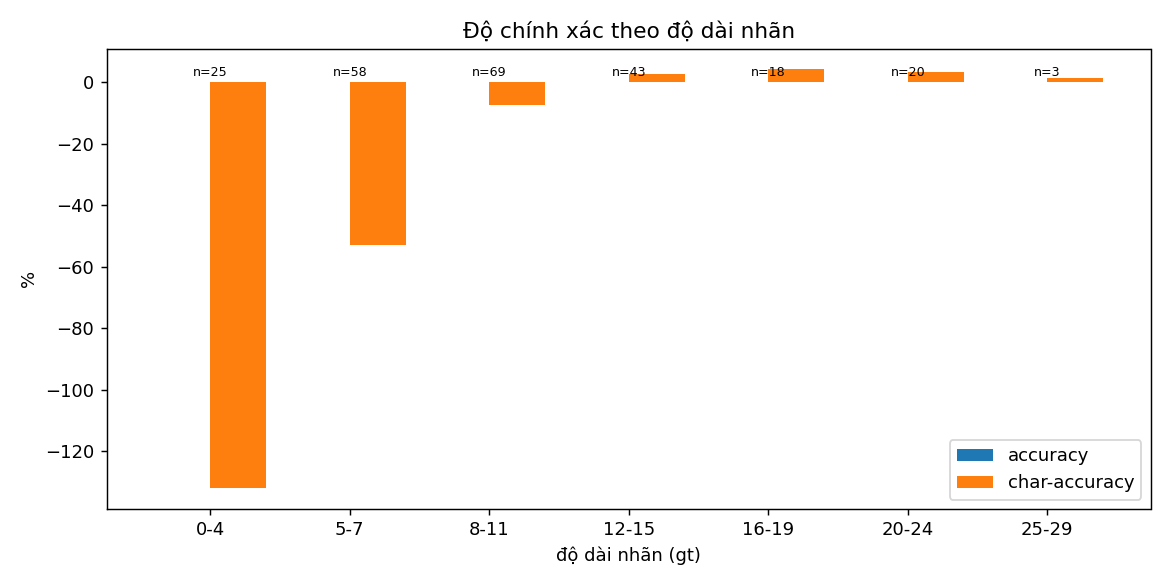

top_errors -> /media/zaibachkhoa/AC84-F995/trademark_data/processed/eda_figures/err_top_samples.png


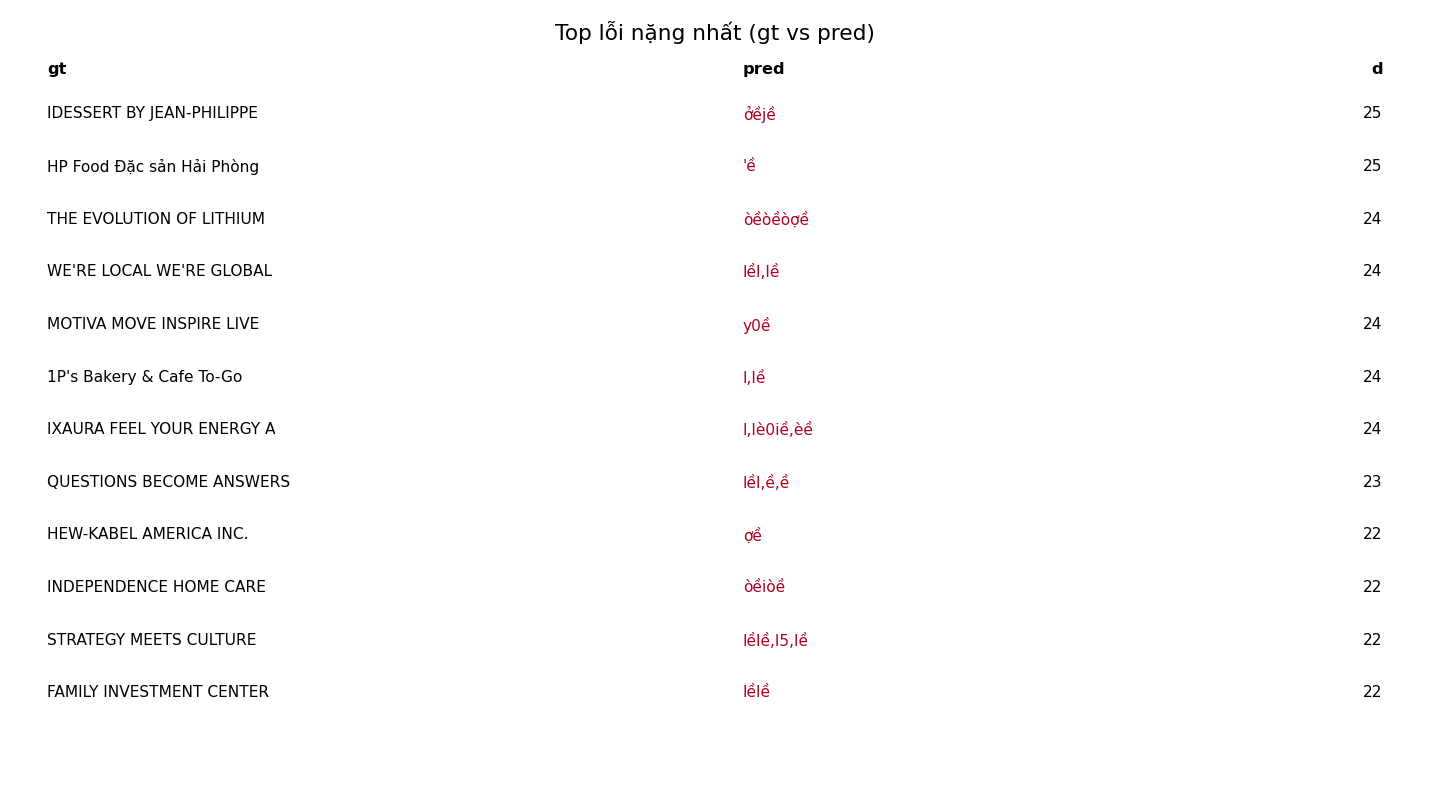

confusions -> /media/zaibachkhoa/AC84-F995/trademark_data/processed/eda_figures/err_char_confusions.png


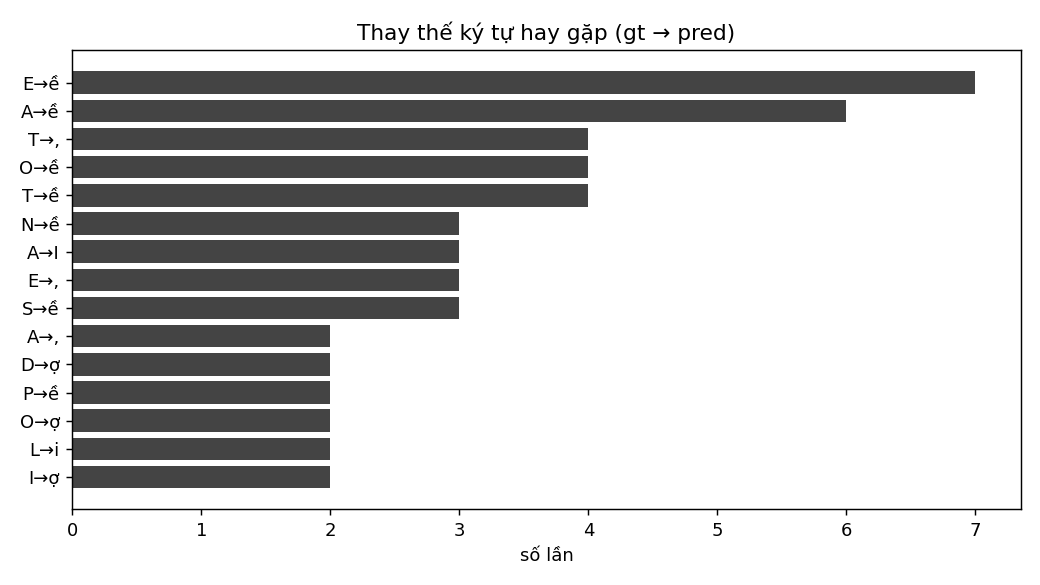

In [7]:
from IPython.display import Image, display as disp

for name, path in (res.get('figures') or {}).items():
    print(name, '->', path)
    disp(Image(filename=path))

### Nhận xét
- Lỗi tăng theo **độ dài nhãn** (nhãn càng dài càng khó).
- Top lỗi cho thấy điểm yếu cụ thể (dấu tiếng Việt, ký tự dễ nhầm).
- Bảng thay thế ký tự dùng để chọn bước hậu xử lý / tăng dữ liệu.

Chạy lại sau khi huấn luyện để so sánh trước/sau.